## Section 1 – Environment setup

In [21]:
!pip install -q -U yfinance lxml html5lib
import yfinance; print('yfinance', yfinance.__version__)

yfinance 1.8.0


## Section 2 – Google Drive connection
Creates `CRM_CM_Coursework` sub-folders automatically. Change `BASE` only if your Drive folder is elsewhere.

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/CRM &CM/CRM_CM_Coursework'
assert os.path.isdir(BASE), f'Folder not found: {BASE} – create it in Drive first'
for sub in ['01_Notebooks','02_Data/Raw','02_Data/Processed','03_Outputs','05_Submission']: os.makedirs(f'{BASE}/{sub}', exist_ok=True)
os.environ['CRM_BASE'] = BASE
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['01_Notebooks', '02_Data', '03_Outputs', '05_Submission']


# 6BUIS017W CWK1 – Market Analysis and Stock Segmentation Using RFM
Student: Nadina Weerawardana (W2121133).

## 0. Setup

In [24]:
import os, io, json, sys, time, datetime as dt, warnings
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")

START, END = "2021-01-01", "2025-01-01"      # END is exclusive
BENCH = "^GSPC"
SEED = 42
N_INIT = 50                                   # K-means initialisations
K_RANGE = range(2, 9)
HV_MULT, BASE_WIN, RFM_WIN = 2.0, 20, 60      # high-volume rule, baseline sessions, RFM window
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
BASE = os.environ.get("CRM_BASE")              # set by the Colab Drive cell; None when run from a GitHub clone
DATA_DIR = f"{BASE}/02_Data/Raw" if BASE else "data"
OUT_DIR = f"{BASE}/03_Outputs" if BASE else "outputs"
PROC_DIR = f"{BASE}/02_Data/Processed" if BASE else "data"
USE_CACHE = True
K_OVERRIDE = {}   # e.g. {"ward_rr": 4}; leave empty to use the automatic rule, then justify in report
[os.makedirs(p, exist_ok=True) for p in (DATA_DIR, OUT_DIR, PROC_DIR)]
sns.set_theme(style="whitegrid")

## 1. Task 1.1 – Constituents and price download (yfinance, auto_adjust=False)

In [25]:
FIELDS = {"adj": "Adj Close", "close": "Close", "high": "High", "low": "Low", "volume": "Volume"}
CACHE = {k: f"{DATA_DIR}/{k}.csv" for k in ["constituents", "bench"] + list(FIELDS)}

def get_constituents():
    html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    t = pd.read_html(io.StringIO(html))[0]
    t["yf_ticker"] = t["Symbol"].str.replace(".", "-", regex=False)   # BRK.B -> BRK-B
    t["retrieval_date"] = dt.date.today().isoformat()
    return t

def _dl(tk, tries=3):
    """Download with retries. auto_adjust=False keeps BOTH 'Close' (split-adjusted) and 'Adj Close' (split+dividend adjusted)."""
    import yfinance as yf
    for a in range(tries):
        try:
            d = yf.download(tk, start=START, end=END, interval="1d", auto_adjust=False, progress=False, threads=True)
            if len(d):
                if not isinstance(d.columns, pd.MultiIndex): d.columns = pd.MultiIndex.from_product([d.columns, list(tk)])
                return d
        except Exception as e: print(f"  retry {a+1}: {e}")
        time.sleep(3 * (a + 1))
    return pd.DataFrame()

def download_prices(tickers):
    import yfinance as yf
    raw = pd.concat([_dl(tickers[i:i+100]) for i in range(0, len(tickers), 100)], axis=1)
    miss = [t for t in tickers if t not in raw["Adj Close"].columns or raw["Adj Close"][t].isna().all()]
    if miss:                                               # one retry for tickers that failed in batch mode
        print("Retrying", len(miss), "tickers individually-in-batches of 20")
        extra = pd.concat([_dl(miss[i:i+20]) for i in range(0, len(miss), 20)], axis=1)
        raw = pd.concat([raw.drop(columns=miss, level=1, errors="ignore"), extra], axis=1)
    b = yf.download(BENCH, start=START, end=END, interval="1d", auto_adjust=False, progress=False)
    if isinstance(b.columns, pd.MultiIndex): b.columns = b.columns.get_level_values(0)
    assert len(raw) and len(b), "Download returned nothing – rerun later or use cached CSVs (see README)"
    return {k: raw[v] for k, v in FIELDS.items()}, b

if USE_CACHE and all(os.path.exists(p) for p in CACHE.values()):
    cons = pd.read_csv(CACHE["constituents"])
    D = {k: pd.read_csv(CACHE[k], index_col=0, parse_dates=True) for k in FIELDS}
    bench = pd.read_csv(CACHE["bench"], index_col=0, parse_dates=True)
    print("Loaded cached snapshot from", DATA_DIR)
else:
    import yfinance as yf; print("yfinance", yf.__version__)
    cons = get_constituents()
    D, bench = download_prices(cons["yf_ticker"].tolist())
    cons.to_csv(CACHE["constituents"], index=False); bench.to_csv(CACHE["bench"])
    for k in FIELDS: D[k].to_csv(CACHE[k])
    print("Downloaded and saved snapshot to", DATA_DIR)
adj, close, vol, high, low = D["adj"], D["close"], D["volume"], D["high"], D["low"]
for d in (adj, close, vol, high, low, bench): d.index = pd.to_datetime(d.index).tz_localize(None)
retrieval_date = str(cons["retrieval_date"].iloc[0])

Loaded cached snapshot from /content/drive/MyDrive/CRM &CM/CRM_CM_Coursework/02_Data/Raw


## 1.1b Dataset validation display (Section 4 checks)

In [26]:
print("Shapes (days x tickers): adj", adj.shape, "| close", close.shape, "| volume", vol.shape, "| benchmark", bench.shape)
print("Benchmark columns:", list(bench.columns)); print("Dtypes OK (all float):", all(d.dtypes.map(pd.api.types.is_float_dtype).all() for d in (adj, close, vol)))
print("Retrieval date:", retrieval_date, "| constituents listed:", len(cons))
print("Date range:", adj.index.min().date(), "->", adj.index.max().date(), "| chronological:", adj.index.is_monotonic_increasing)
assert adj.index.min() >= pd.Timestamp(START) and adj.index.max() < pd.Timestamp(END), "Data outside required window"
assert adj.index.min() <= pd.Timestamp("2021-01-08") and adj.index.max() >= pd.Timestamp("2024-12-27"), "Required period not covered"
gaps = adj.index.to_series().diff().dt.days; print("Largest gap between trading days:", int(gaps.max()), "days (expect <=4, or 5 around holidays)")
print("Tickers returned:", adj.shape[1], "of", len(cons), "| missing:", sorted(set(cons.yf_ticker) - set(adj.columns))[:20])
print("\nFirst rows (Adj Close, 5 tickers):"); print(adj.iloc[:3, :5].round(2).to_string())
print("\nLast rows (Adj Close, 5 tickers):"); print(adj.iloc[-3:, :5].round(2).to_string())
print("\nMissing values per field:", {k: int(D[k].isna().sum().sum()) for k in D})
tol = 1e-6
bad = ((close > high * (1 + tol)) | (close < low * (1 - tol))).sum()
print("OHLC consistency – tickers with any Close outside [Low, High]:", int((bad > 0).sum()), "(report only; yfinance is not an official feed)")

Shapes (days x tickers): adj (1005, 498) | close (1005, 498) | volume (1005, 498) | benchmark (1005, 6)
Benchmark columns: ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
Dtypes OK (all float): False
Retrieval date: 2026-11-22 | constituents listed: 503
Date range: 2021-01-04 -> 2024-12-31 | chronological: True
Largest gap between trading days: 4 days (expect <=4, or 5 around holidays)
Tickers returned: 498 of 503 | missing: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']

First rows (Adj Close, 5 tickers):
                 A    AAPL   ABBV    ABNB    ABT
Date                                            
2021-01-04  114.01  125.54  84.22  139.15  97.27
2021-01-05  114.94  127.09  85.09  148.30  98.47
2021-01-06  118.09  122.81  84.35  142.77  98.27

Last rows (Adj Close, 5 tickers):
                 A    AAPL    ABBV    ABNB     ABT
Date                                              
2024-12-27  133.45  253.56  167.00  133.38  110.11
2024-12-30  132.35  250.19  165.30  131.81  108.02
2024-

## 1.2 Validation, exclusions, corporate-action checks (no silent filling)

In [27]:
log = []
def dup_dates(df): return int(df.index.duplicated().sum())
print("Duplicate dates -> adj/close/vol/bench:", dup_dates(adj), dup_dates(close), dup_dates(vol), dup_dates(bench))
adj, close, vol, bench = [d[~d.index.duplicated(keep="first")].sort_index() for d in (adj, close, vol, bench)]
cal = bench.index                                           # master calendar = benchmark trading days
adj, close, vol = [d.reindex(cal) for d in (adj, close, vol)]  # exposes missing days as NaN (not filled)

b_ok = bench["Adj Close"].notna().all() and (bench["Adj Close"] > 0).all()
print("Benchmark valid:", b_ok, "| trading days:", len(cal))
assert b_ok, "Benchmark failed validation"

def has_split(t):
    """True if yfinance records a split inside the study window (or cannot be checked)."""
    try:
        import yfinance as yf
        s = yf.Ticker(t).splits; s.index = pd.to_datetime(s.index).tz_localize(None)
        return bool(((s.index >= START) & (s.index < END)).any())
    except Exception: return True

keep = []
for _, r in cons.iterrows():
    t = r["yf_ticker"]; why = []
    if t not in adj.columns: why.append("no data returned")
    else:
        a, c, v = adj[t], close[t], vol[t]
        if a.isna().any() or c.isna().any() or v.isna().any():
            why.append(f"missing values/unequal history ({int(a.isna().sum())} missing adj days)")
        else:
            if (a <= 0).any() or (c <= 0).any(): why.append("non-positive price")
            if (v <= 0).any(): why.append("zero/negative volume day")
            if a.pct_change().abs().max() > 0.5 and has_split(t):
              why.append("extreme jump coinciding with a split in the window - adjustment unverified")
    log.append({"ticker": t, "company": r["Security"], "sector": r["GICS Sector"],
                "included": not why, "reason": "; ".join(why) if why else "passed all rules"})
    if not why: keep.append(t)
excl = pd.DataFrame(log)
print(excl["included"].value_counts().to_string()); print(excl[~excl["included"]].head(15).to_string(index=False))
adj, close, vol = adj[keep], close[keep], vol[keep]

# Corporate-action evidence: yfinance Close is split-adjusted; Adj Close is also dividend-adjusted.
ratio = (adj / close)
print("Adj/Close ratio at start – median:", round(ratio.iloc[0].median(), 4), "| share of tickers with ratio<1 at start:",
      round((ratio.iloc[0] < 0.9999).mean(), 3), "(dividend adjustment)")
print("Largest single-day |Close| moves among retained shares (check no unadjusted splits):")
print(close.pct_change().abs().max().sort_values(ascending=False).head(5).round(3).to_string())

Duplicate dates -> adj/close/vol/bench: 0 0 0 0
Benchmark valid: True | trading days: 1005
included
True     486
False     17
ticker              company                 sector  included                                                reason
   APP             AppLovin Communication Services     False  missing values/unequal history (70 missing adj days)
  COIN             Coinbase             Financials     False  missing values/unequal history (69 missing adj days)
   CEG Constellation Energy              Utilities     False missing values/unequal history (263 missing adj days)
   EXE        Expand Energy                 Energy     False  missing values/unequal history (26 missing adj days)
  FDXF        FedEx Freight            Industrials     False                                      no data returned
  FERG Ferguson Enterprises            Industrials     False                              zero/negative volume day
  GEHC        GE HealthCare            Health Care     False missing 

## 2. Task 1.3 – Weekly return (Friday-ending) and weekly beta

In [28]:
def weekly_prices(df):
    w = df.resample("W-FRI").last()                          # last available trading price in each Friday-ending week
    first, last = df.index.min(), df.index.max()
    drop = [lab for lab in w.index if lab > last + pd.Timedelta(days=1)]                       # incomplete final week
    lab0 = w.index[0]
    if first > (lab0 - pd.Timedelta(days=4)) + pd.Timedelta(days=1): drop.append(lab0)         # incomplete first week
    return w.drop(index=drop)                                # holiday-shortened weeks are retained

wk_adj = weekly_prices(adj); wk_b = weekly_prices(bench[["Adj Close"]])["Adj Close"]
assert wk_adj.isna().sum().sum() == 0, "Missing weekly prices – investigate, do not fill"
ret_w = wk_adj.pct_change(fill_method=None).iloc[1:]         # week t / week t-1 - 1
ret_b = wk_b.pct_change(fill_method=None).iloc[1:]
common_weeks = ret_w.index.intersection(ret_b.index)
ret_w, ret_b = ret_w.loc[common_weeks], ret_b.loc[common_weeks]
assert (ret_w.index == ret_b.index).all()
n_weeks = len(common_weeks)
print(f"Aligned weekly return observations: {n_weeks} ({common_weeks.min().date()} to {common_weeks.max().date()})")
mean_ret = ret_w.mean()                                      # arithmetic mean weekly return
beta = ret_w.apply(lambda s: s.cov(ret_b)) / ret_b.var()     # cov(share, mkt)/var(mkt), both ddof=1
print(pd.DataFrame({"mean_weekly_return": mean_ret, "beta": beta}).describe().round(4).to_string())

Aligned weekly return observations: 207 (2021-01-15 to 2024-12-27)
       mean_weekly_return      beta
count            486.0000  486.0000
mean               0.0029    0.9737
std                0.0027    0.4073
min               -0.0045    0.0555
25%                0.0012    0.6666
50%                0.0026    0.9506
75%                0.0042    1.1795
max                0.0178    3.7786


## 3. Task 1.4 – Adapted RFM (observation date = last common completed trading date)

In [29]:
obs_date = vol.dropna(how="any").index.max()
assert len(vol) >= BASE_WIN + RFM_WIN, "Insufficient history for 20-session baseline + 60-session window"
baseline = vol.shift(1).rolling(BASE_WIN).mean()             # preceding 20 sessions, excludes day tested (no look-ahead)
threshold = HV_MULT * baseline
event = (vol > threshold) & baseline.notna()                 # volume strictly > 2 x baseline
last_evt = event.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
R = (obs_date - pd.to_datetime(last_evt)).dt.days            # calendar days; same-day event => 0; no event => NaN (not 0)
F = event.iloc[-RFM_WIN:].sum()                              # qualifying days in latest 60 sessions
M = (close * vol).iloc[-RFM_WIN:].sum()                      # approx traded value (USD), 60 sessions
window_start = vol.index[-RFM_WIN]
print("Observation date:", obs_date.date(), "| 60-session window:", window_start.date(), "to", obs_date.date())
print("Shares with no event in history (excluded from RFM):", int(R.isna().sum()))

ex = "AAPL" if "AAPL" in keep else keep[0]
print(f"\n--- Worked example: {ex} ---")
w = pd.DataFrame({"Volume": vol[ex], "Base20": baseline[ex], "Threshold": threshold[ex], "Event": event[ex]}).iloc[-RFM_WIN:]
print(w[w.Event].to_string() if w.Event.any() else "No events in window")
print(f"Last event: {last_evt[ex]} | obs date: {obs_date.date()} | R = {R[ex]} days | F = {F[ex]} | M = ${M[ex]:,.0f}")
print("M check: sum of Close*Volume over", RFM_WIN, "sessions =", f"{(close[ex].iloc[-RFM_WIN:]*vol[ex].iloc[-RFM_WIN:]).sum():,.0f}")
print(f"Return/Beta example: mean weekly return {mean_ret[ex]:.5f}, beta {beta[ex]:.4f}, n_weeks {n_weeks}")
same_day = event.iloc[-1]
assert ((R == 0) == same_day).all(), "Same-day event should give R=0"
print("Same-day events (R=0):", int((R == 0).sum()), "| F range:", int(F.min()), "-", int(F.max()))

Observation date: 2024-12-31 | 60-session window: 2024-10-07 to 2024-12-31
Shares with no event in history (excluded from RFM): 0

--- Worked example: AAPL ---
               Volume      Base20   Threshold  Event
Date                                                
2024-11-25   90152800  43820740.0  87641480.0   True
2024-12-20  147495300  45004605.0  90009210.0   True
Last event: 2024-12-20 00:00:00 | obs date: 2024-12-31 | R = 11 days | F = 2 | M = $623,303,377,707
M check: sum of Close*Volume over 60 sessions = 623,303,377,707
Return/Beta example: mean weekly return 0.00393, beta 1.1748, n_weeks 207
Same-day events (R=0): 0 | F range: 0 - 8


## 3b. Task 1.5 – Feature table, summaries, common valid share set

In [30]:
feat = pd.DataFrame({"mean_weekly_return": mean_ret, "beta": beta, "R": R, "F": F, "M": M})
feat["sector"] = cons.set_index("yf_ticker").loc[feat.index, "GICS Sector"]
feat["company"] = cons.set_index("yf_ticker").loc[feat.index, "Security"]
valid = feat.dropna(subset=["mean_weekly_return", "beta", "R", "F", "M"]).copy()
for t in feat.index.difference(valid.index): excl.loc[excl.ticker == t, ["included", "reason"]] = [False, "no qualifying high-volume event (R missing)"]
print("Common valid share set:", len(valid))
base5 = ["mean_weekly_return", "beta", "R", "F", "M"]
print(valid[base5].describe().round(4).to_string())
print("Skewness:", valid[base5].apply(skew).round(2).to_dict())

Common valid share set: 486
       mean_weekly_return      beta         R         F             M
count            486.0000  486.0000  486.0000  486.0000  4.860000e+02
mean               0.0029    0.9737   20.4074    2.9897  3.940419e+10
std                0.0027    0.4073   21.3424    1.3308  1.291388e+11
min               -0.0045    0.0555    4.0000    0.0000  1.297483e+09
25%                0.0012    0.6666   11.0000    2.0000  1.019517e+10
50%                0.0026    0.9506   11.0000    3.0000  1.668382e+10
75%                0.0042    1.1795   14.7500    4.0000  3.227689e+10
max                0.0178    3.7786  222.0000    8.0000  1.847697e+12
Skewness: {'mean_weekly_return': 0.86, 'beta': 1.1, 'R': 3.63, 'F': 0.42, 'M': 11.65}


## 4. Task 2.1 – Feature matrices, skew/outlier checks, log1p(M), standardisation

In [31]:
valid["logM"] = np.log1p(valid["M"])
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
diag = pd.DataFrame({"skew": valid[base5 + ["logM"]].apply(skew), "IQR_outliers": valid[base5 + ["logM"]].apply(iqr_outliers)})
print(diag.round(3).to_string())
# R and F kept untransformed; outliers retained (not trimmed) and discussed in report. Only M is log1p-transformed as required.
X_rr_raw = valid[["mean_weekly_return", "beta"]]
X_rfm_raw = valid[["R", "F", "logM"]]
X = {"rr": StandardScaler().fit_transform(X_rr_raw), "rfm": StandardScaler().fit_transform(X_rfm_raw)}
names = {"rr": "Risk-Return", "rfm": "RFM"}

                      skew  IQR_outliers
mean_weekly_return   0.865            15
beta                 1.100            10
R                    3.635           115
F                    0.423             2
M                   11.648            45
logM                 1.076            13


## 5. Task 2.2 – Ward agglomerative clustering (Euclidean, standardised)

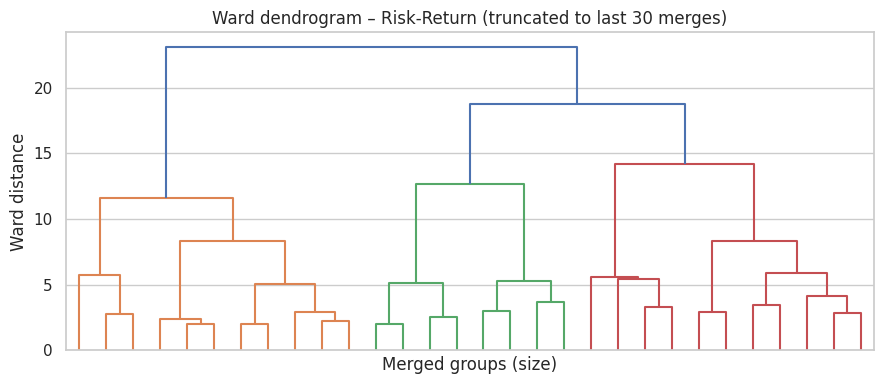


Ward – Risk-Return
    silhouette  min_size  max_size                             sizes
k                                                                  
2       0.339        92       394                         [394, 92]
3       0.274        92       230                    [230, 92, 164]
4       0.282        48       182                [164, 92, 182, 48]
5       0.304        48       182             [92, 48, 182, 98, 66]
6       0.320         5       182          [182, 48, 87, 98, 66, 5]
7       0.324         5       160      [87, 48, 160, 98, 66, 5, 22]
8       0.321         5       160  [160, 48, 5, 98, 66, 31, 22, 56] 
Selected k = 2


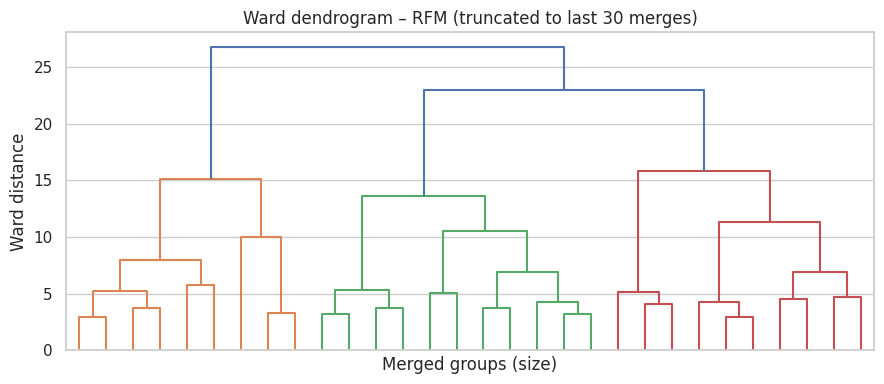


Ward – RFM
    silhouette  min_size  max_size                              sizes
k                                                                   
2       0.368        82       404                          [404, 82]
3       0.304        82       250                     [250, 82, 154]
4       0.289        43       207                 [82, 207, 154, 43]
5       0.305        10       207             [154, 207, 10, 43, 72]
6       0.314        10       207         [207, 136, 10, 43, 72, 18]
7       0.292        10       141     [136, 72, 10, 43, 141, 18, 66]
8       0.302        10       141  [10, 72, 79, 43, 141, 18, 66, 57] 
Selected k = 2


In [32]:
def pick_k(sc):
    ok = sc[sc["min_size"] >= max(5, int(0.03 * len(valid)))]
    return int((ok if len(ok) else sc)["silhouette"].idxmax())
diagnostics, labels, chosen = {}, {}, {}
for key in X:
    Z = linkage(X[key], method="ward", metric="euclidean")
    plt.figure(figsize=(9, 4)); dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
    plt.title(f"Ward dendrogram – {names[key]} (truncated to last 30 merges)"); plt.xlabel("Merged groups (size)"); plt.ylabel("Ward distance")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/dendrogram_{key}.png", dpi=200); plt.show()
    rows = []
    for k in K_RANGE:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X[key])
        sz = np.bincount(lab); rows.append({"k": k, "silhouette": silhouette_score(X[key], lab), "min_size": sz.min(), "max_size": sz.max(), "sizes": sz.tolist()})
    sc = pd.DataFrame(rows).set_index("k"); diagnostics[f"ward_{key}"] = sc
    chosen[f"ward_{key}"] = K_OVERRIDE.get(f"ward_{key}", pick_k(sc))
    labels[f"ward_{key}"] = AgglomerativeClustering(n_clusters=chosen[f"ward_{key}"], linkage="ward").fit_predict(X[key])
    print(f"\nWard – {names[key]}\n", sc.round(3).to_string(), "\nSelected k =", chosen[f"ward_{key}"])

## 6. Task 2.3 – K-means (seeded, multiple initialisations)


K-means – Risk-Return
    silhouette  inertia  min_size  max_size                             sizes
k                                                                           
2       0.387  621.634       143       343                        [143, 343]
3       0.329  461.179       119       202                   [202, 165, 119]
4       0.327  371.577        40       160               [132, 154, 40, 160]
5       0.341  309.613        27       166           [112, 166, 131, 27, 50]
6       0.335  265.097         5       156        [156, 127, 50, 105, 43, 5]
7       0.328  227.183         5       128     [103, 85, 41, 128, 77, 47, 5]
8       0.354  194.362         5       136  [136, 43, 76, 78, 5, 29, 40, 79] 
Selected k = 2


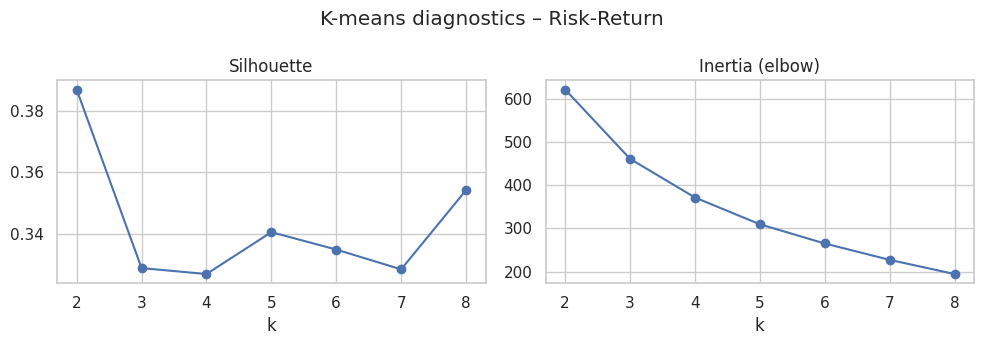


K-means – RFM
    silhouette   inertia  min_size  max_size                              sizes
k                                                                             
2       0.423  1066.832        68       418                          [418, 68]
3       0.325   796.614        64       270                     [270, 152, 64]
4       0.341   609.832        61       212                 [122, 61, 212, 91]
5       0.358   514.714        11       198             [68, 122, 87, 11, 198]
6       0.347   437.393        11       143        [105, 143, 40, 11, 120, 67]
7       0.347   386.286         1       141     [141, 41, 104, 120, 1, 68, 11]
8       0.350   342.175         1       140  [15, 106, 64, 66, 1, 11, 140, 83] 
Selected k = 2


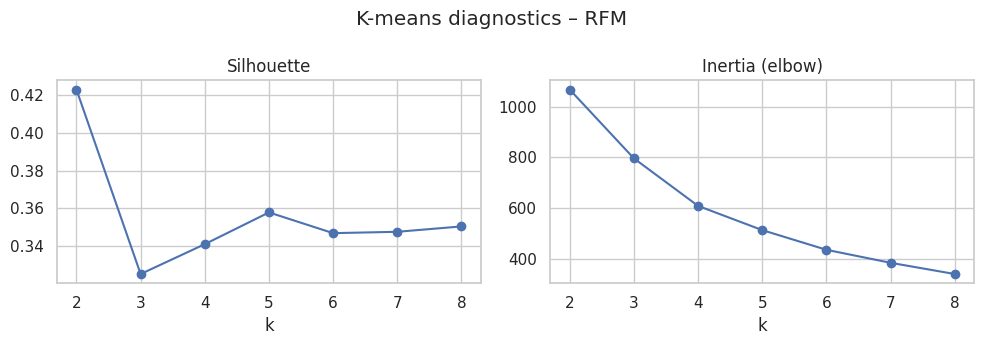

In [33]:
for key in X:
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X[key])
        sz = np.bincount(km.labels_); rows.append({"k": k, "silhouette": silhouette_score(X[key], km.labels_), "inertia": km.inertia_, "min_size": sz.min(), "max_size": sz.max(), "sizes": sz.tolist()})
    sc = pd.DataFrame(rows).set_index("k"); diagnostics[f"kmeans_{key}"] = sc
    chosen[f"kmeans_{key}"] = K_OVERRIDE.get(f"kmeans_{key}", pick_k(sc))
    labels[f"kmeans_{key}"] = KMeans(n_clusters=chosen[f"kmeans_{key}"], n_init=N_INIT, random_state=SEED).fit_predict(X[key])
    print(f"\nK-means – {names[key]}\n", sc.round(3).to_string(), "\nSelected k =", chosen[f"kmeans_{key}"])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5)); sc["silhouette"].plot(marker="o", ax=ax[0], title="Silhouette"); sc["inertia"].plot(marker="o", ax=ax[1], title="Inertia (elbow)")
    fig.suptitle(f"K-means diagnostics – {names[key]}"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/kmeans_diag_{key}.png", dpi=200); plt.show()
for name, sc in diagnostics.items(): sc.to_csv(f"{OUT_DIR}/diagnostics_{name}.csv")

## 7. Task 2.4 – Profiles in original units, 2-D visualisation, algorithm comparison


Profile (median, original units) – ward_rr
          mean_weekly_return    beta  n_shares
ward_rr                                      
0                    0.0021  0.8817       394
1                    0.0055  1.2177        92

Profile (median, original units) – ward_rfm
              R    F             M  n_shares
ward_rfm                                   
0         11.0  3.0  1.604728e+10       404
1         54.5  2.0  1.784903e+10        82

Profile (median, original units) – kmeans_rr
            mean_weekly_return    beta  n_shares
kmeans_rr                                      
0                      0.0049  1.2781       143
1                      0.0019  0.8340       343

Profile (median, original units) – kmeans_rfm
                R    F             M  n_shares
kmeans_rfm                                   
0           11.0  3.0  1.556962e+10       418
1           55.0  2.0  2.225004e+10        68


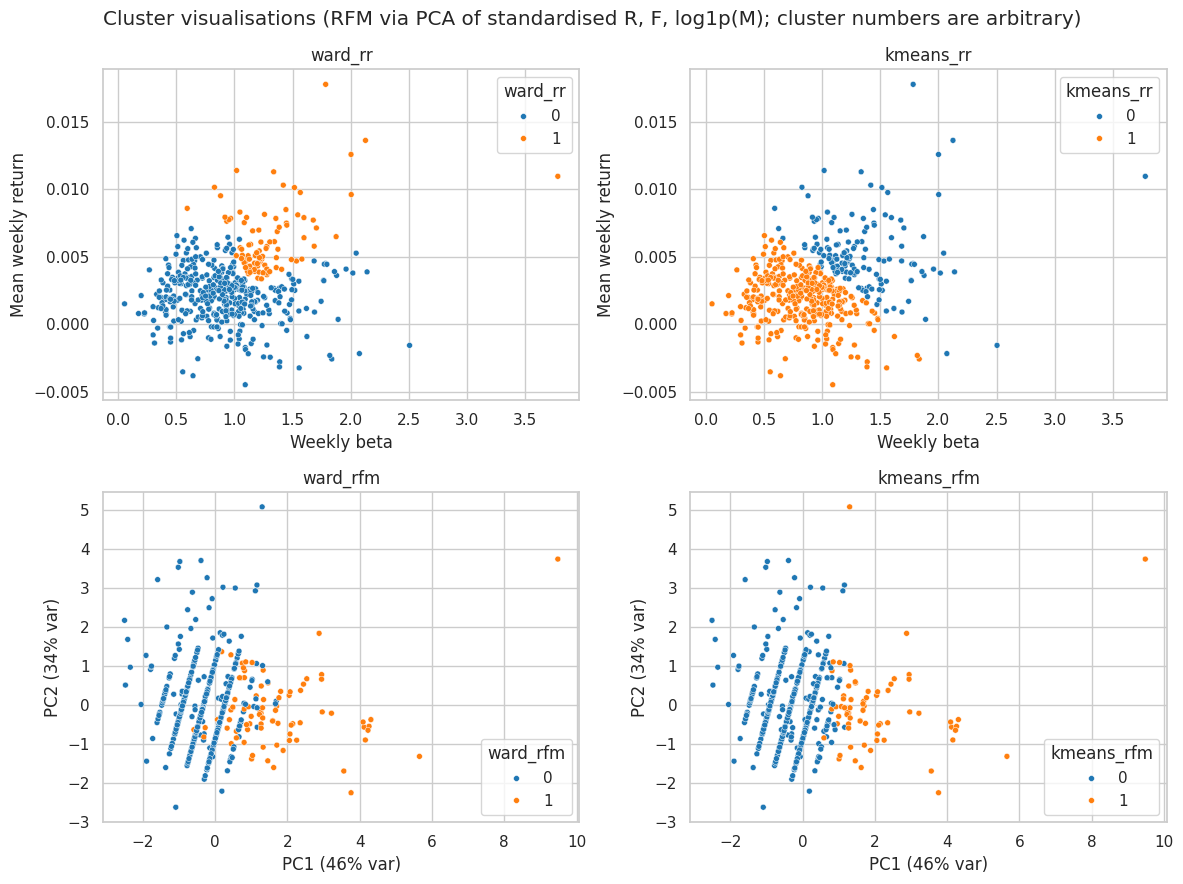


Ward vs K-means ARI (same shares): {'rr': 0.598, 'rfm': 0.7}
kmeans   0    1
ward           
0       51  343
1       92    0 

kmeans    0   1
ward           
0       396   8
1        22  60 



In [34]:
for name, lab in labels.items(): valid[name] = lab
orig = {"rr": ["mean_weekly_return", "beta"], "rfm": ["R", "F", "M"]}
for name in labels:
    key = name.split("_")[1]
    p = valid.groupby(name)[orig[key]].median().join(valid.groupby(name).size().rename("n_shares"))
    p.to_csv(f"{OUT_DIR}/profile_{name}.csv"); print(f"\nProfile (median, original units) – {name}\n", p.round(4).to_string())
pca = PCA(n_components=2, random_state=SEED).fit(X["rfm"]); P = pca.transform(X["rfm"])
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, name in zip(axes.ravel(), ["ward_rr", "kmeans_rr", "ward_rfm", "kmeans_rfm"]):
    key = name.split("_")[1]
    if key == "rr": x, y, xl, yl = valid.beta, valid.mean_weekly_return, "Weekly beta", "Mean weekly return"
    else: x, y, xl, yl = P[:, 0], P[:, 1], f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)", f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)"
    sns.scatterplot(x=x, y=y, hue=valid[name], palette="tab10", s=18, ax=ax); ax.set_title(name); ax.set_xlabel(xl); ax.set_ylabel(yl)
plt.suptitle("Cluster visualisations (RFM via PCA of standardised R, F, log1p(M); cluster numbers are arbitrary)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cluster_scatter.png", dpi=200); plt.show()
ari = {k: adjusted_rand_score(valid[f"ward_{k}"], valid[f"kmeans_{k}"]) for k in X}
print("\nWard vs K-means ARI (same shares):", {k: round(v, 3) for k, v in ari.items()})
for k in X: print(pd.crosstab(valid[f"ward_{k}"], valid[f"kmeans_{k}"], rownames=["ward"], colnames=["kmeans"]).to_string(), "\n")

## 8. Task 2.5 – Correlations and removal of Monetary

Pearson:
           R      F   logM
R     1.000 -0.346  0.152
F    -0.346  1.000  0.013
logM  0.152  0.013  1.000 
Spearman:
           R      F   logM
R     1.000 -0.196  0.137
F    -0.196  1.000 -0.048
logM  0.137 -0.048  1.000


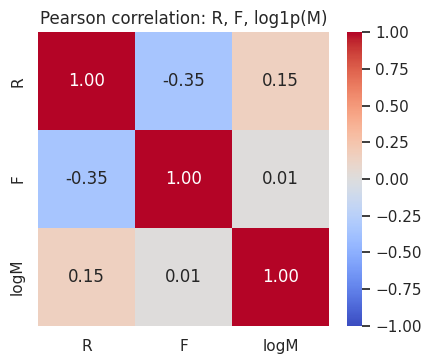


ARI (Ward RFM vs Ward R,F only; k=2, same 486 shares): 0.873
R,F only    0   1
RFM              
0         394  10
1           3  79

Traded-value profile by ward_rfm
              R    F             M  avg_daily_traded_value    n
ward_rfm                                                      
0         11.0  3.0  1.604728e+10             267454628.0  404
1         54.5  2.0  1.784903e+10             297483782.5   82

Traded-value profile by ward_rf_only
                  R    F             M  avg_daily_traded_value    n
ward_rf_only                                                      
0             11.0  3.0  1.546400e+10             257733301.4  397
1             54.0  2.0  2.084781e+10             347463505.0   89


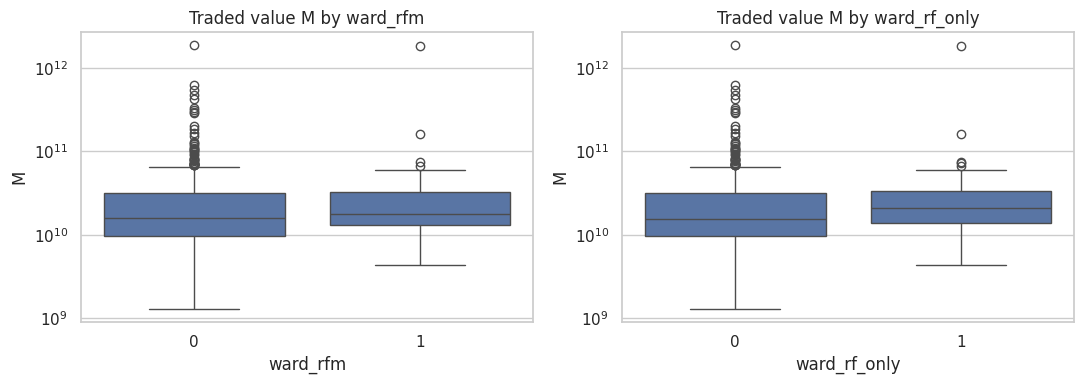

In [35]:
corr_p = valid[["R", "F", "logM"]].corr(); corr_s = valid[["R", "F", "logM"]].corr(method="spearman")
print("Pearson:\n", corr_p.round(3).to_string(), "\nSpearman:\n", corr_s.round(3).to_string())
corr_p.to_csv(f"{OUT_DIR}/rfm_correlation_pearson.csv"); corr_s.to_csv(f"{OUT_DIR}/rfm_correlation_spearman.csv")
plt.figure(figsize=(4.5, 3.8)); sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1); plt.title("Pearson correlation: R, F, log1p(M)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rfm_corr_heatmap.png", dpi=200); plt.show()
k_rfm = chosen["ward_rfm"]
X_rf = StandardScaler().fit_transform(valid[["R", "F"]])    # re-standardised afresh
valid["ward_rf_only"] = AgglomerativeClustering(n_clusters=k_rfm, linkage="ward").fit_predict(X_rf)
ari_rm = adjusted_rand_score(valid["ward_rfm"], valid["ward_rf_only"])
print(f"\nARI (Ward RFM vs Ward R,F only; k={k_rfm}, same {len(valid)} shares): {ari_rm:.3f}")
print(pd.crosstab(valid["ward_rfm"], valid["ward_rf_only"], rownames=["RFM"], colnames=["R,F only"]).to_string())
valid["avg_daily_traded_value"] = valid["M"] / RFM_WIN
tv = {c: valid.groupby(c)[["R", "F", "M"]].median().join(valid.groupby(c)["avg_daily_traded_value"].median()).join(valid.groupby(c).size().rename("n")) for c in ["ward_rfm", "ward_rf_only"]}
for c, t in tv.items(): print(f"\nTraded-value profile by {c}\n", t.round(1).to_string()); t.to_csv(f"{OUT_DIR}/tradedvalue_profile_{c}.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, c in zip(ax, tv): sns.boxplot(data=valid, x=c, y="M", ax=a); a.set_yscale("log"); a.set_title(f"Traded value M by {c}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/monetary_removal_boxplots.png", dpi=200); plt.show()

## 9. Task 3.2.1 – Sector composition

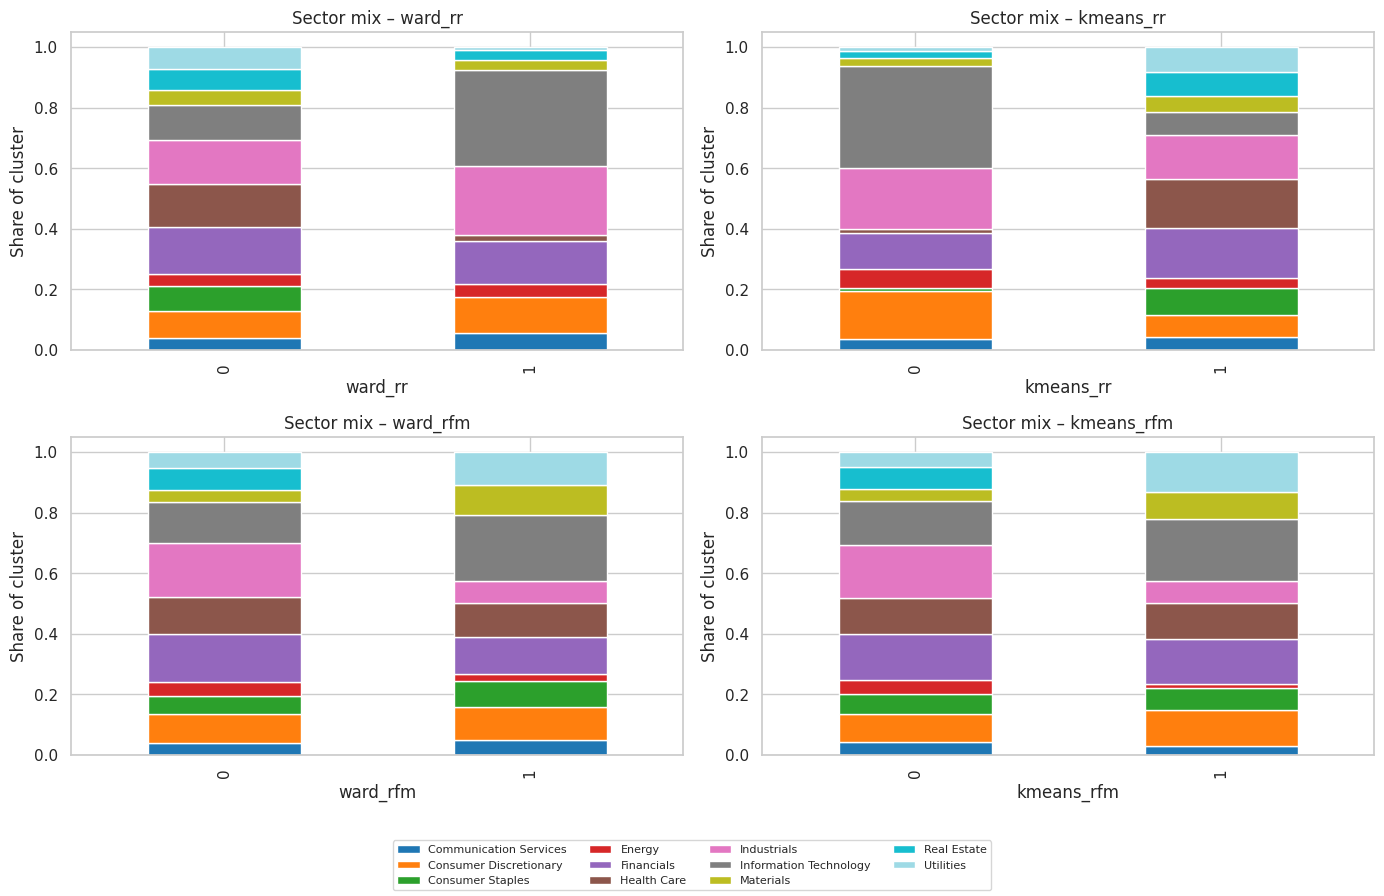

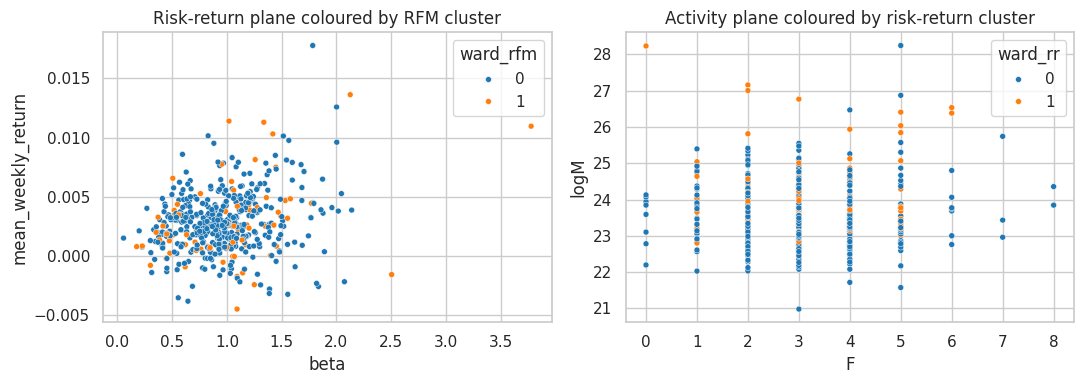

ARI risk-return vs RFM (Ward): 0.029


In [36]:
sol = ["ward_rr", "kmeans_rr", "ward_rfm", "kmeans_rfm"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.ravel(), sol):
    ct = pd.crosstab(valid[name], valid["sector"], normalize="index"); ct.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="tab20"); ax.set_title(f"Sector mix – {name}"); ax.set_ylabel("Share of cluster")
    pd.crosstab(valid[name], valid["sector"]).to_csv(f"{OUT_DIR}/sector_counts_{name}.csv")
h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=4, fontsize=8)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.savefig(f"{OUT_DIR}/sector_composition.png", dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); sns.scatterplot(data=valid, x="beta", y="mean_weekly_return", hue="ward_rfm", palette="tab10", ax=ax[0], s=18); ax[0].set_title("Risk-return plane coloured by RFM cluster")
sns.scatterplot(data=valid, x="F", y="logM", hue="ward_rr", palette="tab10", ax=ax[1], s=18); ax[1].set_title("Activity plane coloured by risk-return cluster"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cross_view.png", dpi=200); plt.show()
print("ARI risk-return vs RFM (Ward):", round(adjusted_rand_score(valid["ward_rr"], valid["ward_rfm"]), 3))

## 10. Save deliverables (feature table, assignments, logs, provenance metadata)

In [37]:
import sklearn, scipy, matplotlib
cols = ["company", "sector", "mean_weekly_return", "beta", "R", "F", "M", "logM", "avg_daily_traded_value"] + sol + ["ward_rf_only"]
valid[cols].to_csv(f"{OUT_DIR}/feature_table_with_clusters.csv"); excl.to_csv(f"{OUT_DIR}/inclusion_exclusion_log.csv", index=False)
meta = {"calc_version": "v1.0", "retrieval_date": retrieval_date, "wikipedia_url": WIKI_URL, "study_start": START, "study_end_exclusive": END,
        "observation_date": str(obs_date.date()), "rfm_window_sessions": RFM_WIN, "baseline_sessions": BASE_WIN, "high_volume_multiplier": HV_MULT,
        "weekly_obs": int(n_weeks), "n_valid_shares": int(len(valid)), "n_listed": int(len(cons)), "seed": SEED, "kmeans_n_init": N_INIT,
        "selected_k": {k: int(v) for k, v in chosen.items()}, "data_source": "yfinance (Yahoo Finance), auto_adjust=False",
        "python": sys.version.split()[0],
        "packages": {"numpy": np.__version__, "pandas": pd.__version__, "seaborn": sns.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}}
try:
    import yfinance; meta["packages"]["yfinance"] = yfinance.__version__
except Exception: pass
weekly_out = ret_w.copy(); weekly_out["^GSPC"] = ret_b; weekly_out.to_csv(f"{PROC_DIR}/weekly_returns_aligned.csv")
json.dump(meta, open(f"{OUT_DIR}/run_metadata.json", "w"), indent=2); print(json.dumps(meta, indent=2)); print("Outputs saved in:", OUT_DIR)

{
  "calc_version": "v1.0",
  "retrieval_date": "2026-11-22",
  "wikipedia_url": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "study_start": "2021-01-01",
  "study_end_exclusive": "2025-01-01",
  "observation_date": "2024-12-31",
  "rfm_window_sessions": 60,
  "baseline_sessions": 20,
  "high_volume_multiplier": 2.0,
  "weekly_obs": 207,
  "n_valid_shares": 486,
  "n_listed": 503,
  "seed": 42,
  "kmeans_n_init": 50,
  "selected_k": {
    "ward_rr": 2,
    "ward_rfm": 2,
    "kmeans_rr": 2,
    "kmeans_rfm": 2
  },
  "data_source": "yfinance (Yahoo Finance), auto_adjust=False",
  "python": "3.13.18",
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "seaborn": "0.13.2",
    "scikit-learn": "1.6.1",
    "scipy": "1.16.3",
    "matplotlib": "3.10.0",
    "yfinance": "1.8.0"
  }
}
Outputs saved in: /content/drive/MyDrive/CRM &CM/CRM_CM_Coursework/03_Outputs
